In [1]:
import glob, pickle, os
import pandas as pd
import numpy as np
import shutil
import matplotlib.pyplot as plt

In [2]:
Fs = 3e4
out_path = './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/'

files_to_analyze = glob.glob(out_path + '*_EncodingModel.pickle')

In [3]:
files_to_analyze

['./dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m29_unit_2_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m30_unit_2_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m31_unit_3_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m23_unit_2_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m20_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m29_unit_3_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m11_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m31_unit_2_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m31_unit_1_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m20_unit_3_EncodingModel.pickle',
 './dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m11_unit_2_EncodingModel.pickle',
 './dataFolder/5_1DCo

In [4]:
idx_up = []
idx_down = []
mothID = []
status = []

for fp in files_to_analyze:
    ID = "_".join(os.path.basename(fp).split('_')[0:3])
    mothID.append(ID)
    
    with open(fp, 'rb') as f:
        data = pickle.load(f)
        sta = np.asarray(data[1]).ravel()
        prior = np.asarray(data[4]).ravel()
        prior_error = np.asarray(data[5]).ravel()
        
    pre_sta = sta[:600]
    pre_prior = prior[:600] 
    pre_error = prior_error[:600]
    
    up = np.where(pre_sta > pre_prior + pre_error)[0]
    down = np.where(pre_sta < pre_prior - pre_error)[0]
    
    # print(ID, 'up:', len(up), 'down:', len(down))

    if len(up) == 0 and len(down) == 0:
        idx_up.append(np.nan)
        idx_down.append(np.nan)
        print(f'{ID} nothing here')
    elif len(up) != 0 and len(down) != 0:
        idx_up.append(up[0])
        idx_down.append(down[0])
        print(f'{ID} has both ends - shucks - I am too tired to type it out')
    elif len(up) != 0:
        idx_up.append(up[0])
        idx_down.append(np.nan)
        print(f'{ID} sta amplitude: {round(pre_sta[int(up[0])],2)} prior mean ± std: {round(pre_prior[int(up[0])], 2)} ± {round(pre_error[int(up[0])], 2)}')
    else:
        idx_up.append(np.nan)
        idx_down.append(down[0])
        print(f'{ID} sta amplitude: {round(pre_sta[int(down[0])],2)} prior mean ± std: {round(pre_prior[int(down[0])], 2)} ± {round(pre_error[int(down[0])], 2)}')
   
    # if len(up) > 0:
    #     idx_up.append(int(up[0]))
    # else:
    #     idx_up.append(np.nan)
    
    # if len(down) > 0:
    #         idx_down.append(int(down[0]))
    # else:
    #     idx_down.append(np.nan)
        
    # peak_idx = np.argmax(np.abs(pre_sta))
    # sta_peak = pre_sta[peak_idx]
    # prior_at_peak = pre_prior[peak_idx]
    # error_at_peak = pre_error[peak_idx]
    
    # print(ID, 'sta peak:', round(sta_peak, 2), 'prior mean ± std:', round(prior_at_peak, 2), '±', round(error_at_peak, 2))

data = pd.DataFrame({'mothID': mothID,
                    'up': idx_up,
                    'down': idx_down})
data['status'] = data['up'].fillna(data['down'])

# print the ampltiude at which this decision was made
filtered = data[data['status'].notna()]
data.to_csv('./dataFolder/5_1DCompModel/' + 'selectedUnits.csv')

m29_unit_2 sta amplitude: 5.55 prior mean ± std: -0.23 ± 5.49
m30_unit_2 sta amplitude: -6.95 prior mean ± std: -0.27 ± 6.53
m31_unit_3 sta amplitude: -5.74 prior mean ± std: -0.2 ± 5.52
m23_unit_2 nothing here
m20_unit_1 nothing here
m29_unit_3 sta amplitude: 5.45 prior mean ± std: -0.22 ± 5.54
m11_unit_1 sta amplitude: 0.79 prior mean ± std: -0.0 ± 0.77
m31_unit_2 sta amplitude: -5.73 prior mean ± std: -0.18 ± 5.53
m31_unit_1 sta amplitude: -5.7 prior mean ± std: -0.2 ± 5.49
m20_unit_3 nothing here
m11_unit_2 sta amplitude: 0.81 prior mean ± std: 0.01 ± 0.77
m20_unit_2 nothing here
m23_unit_1 sta amplitude: 7.31 prior mean ± std: -0.18 ± 7.38
m30_unit_1 sta amplitude: -6.72 prior mean ± std: -0.12 ± 6.52
m29_unit_1 sta amplitude: 5.42 prior mean ± std: -0.28 ± 5.59
m11_unit_3 sta amplitude: 0.83 prior mean ± std: 0.01 ± 0.77


In [5]:
data

,mothID,up,down,status
0,m29_unit_2,554.0,NaN,554.0
1,m30_unit_2,NaN,479.0,479.0
2,m31_unit_3,NaN,542.0,542.0
3,m23_unit_2,NaN,NaN,NaN
4,m20_unit_1,NaN,NaN,NaN
5,m29_unit_3,537.0,NaN,537.0
6,m11_unit_1,531.0,NaN,531.0
7,m31_unit_2,NaN,523.0,523.0
8,m31_unit_1,NaN,560.0,560.0
9,m20_unit_3,NaN,NaN,NaN


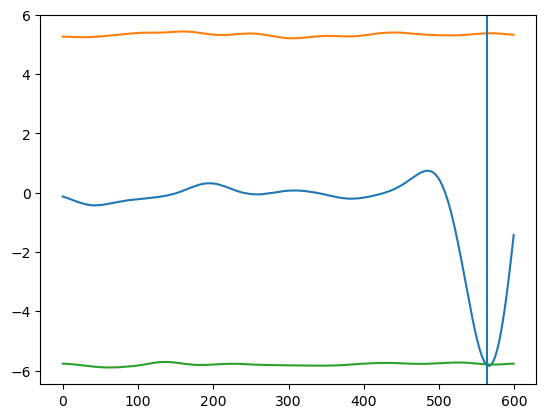

In [20]:
plt.plot(pre_sta)
plt.plot(pre_prior + pre_error)
plt.plot(pre_prior - pre_error)
plt.axvline(563)

## copy the selected files to a new folder for further analysis

In [136]:
# # read the csv with selected units and save model into seprate folder

# out_path = './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/' + 'selectedUnits/'
# os.makedirs(out_path, exist_ok=True)

# list_selected = pd.read_csv('./dataFolder/5_1DCompModel/selectedUnits.csv')
# files_to_analyze = glob.glob('./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/' + '*_EncodingModel.pickle')

In [140]:
# selected = list_selected[list_selected['status'].notna()]
# for name in selected['mothID']:
#     p = [path for path in files_to_analyze if name in path][0]
#     print(p)
#     shutil.copy(p, out_path)

./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/m31_unit_3_EncodingModel.pickle
./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/m31_unit_2_EncodingModel.pickle
./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/m31_unit_1_EncodingModel.pickle
./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/m11_unit_2_EncodingModel.pickle
./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/m23_unit_1_EncodingModel.pickle
./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/m30_unit_1_EncodingModel.pickle
./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/m29_unit_1_EncodingModel.pickle
./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/m11_unit_3_EncodingModel.pickle
